# Data exploration and cleaning

Run the cells from top to bottom.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_DIR = Path("data") if Path("data").exists() else Path("../data")
df = pd.read_csv(DATA_DIR / "original_cars.csv", encoding="cp1251")

## 1. Translate Cyrillic text

Some car and model names contained Cyrillic text. We used the same translations as in `data_cleaning.py`. The pattern below matches Cyrillic characters.

In [2]:
cyrillic_count = df.astype("string").apply(
    lambda column: column.str.count(r"[\u0400-\u052F]")
).sum().sum()
print(f"Cyrillic characters before translation: {int(cyrillic_count)}")

Cyrillic characters before translation: 4997


In [3]:
# Translate Cyrillic model names
model_translations = {
    "1103 Славута": "1103 Slavuta",
    "1102 Таврия": "1102 Tavria",
    "Патриот": "Patriot",
    "969М": "969M",
    "2705 GAZель": "2705 GAZelle",
    "Таврия-Нова": "Tavria-Nova",
    "3302 GAZель": "3302 GAZelle",
    "2752 Соболь": "2752 Sobol",
    "469Б": "469B",
    "Приора": "Priora",
    "969 Волынь": "969 Volyn",
    "3221 GAZель": "3221 GAZelle",
    "2190 Гранта": "2190 Granta",
    "2109 (Балтика)": "2109 (Baltika)",
    "Классические": "Classic"
}

df["model"] = df["model"].replace(model_translations)

# Translate Cyrillic descriptions names
description_translations = {
    "груз.": "Cargo",
    "груз": "Cargo",
    "пасс.": "Passenger",
    "пасс": "Passenger"
}

for original, english in description_translations.items():
    df["model"] = df["model"].str.replace(
        original,
        english,
        regex=False
    )

# Translate Cyrillic car manufacturer names
df["car"] = df["car"].replace({
    "ЛUAZ": "LuAZ"
})

In [4]:
cyrillic_count = df.astype("string").apply(
    lambda column: column.str.count(r"[\u0400-\u052F]")
).sum().sum()
print(f"Cyrillic characters after translation: {int(cyrillic_count)}")

Cyrillic characters after translation: 0


## 2. Remove the engine-volume column

We counted missing `engV` values before removing the column. Engine volume is not applicable to fully electric cars, and other entries are missing or questionable. We drop the column to keep preparation simple.

In [5]:
print(f"Rows missing engV: {df['engV'].isna().sum()}")

Rows missing engV: 434


In [6]:
df = df.drop(columns=["engV"])

In [7]:
print(f"Columns left: {df.columns.tolist()}")

Columns left: ['car', 'price', 'body', 'mileage', 'engType', 'registration', 'year', 'model', 'drive']


## 3. Remove duplicates

We counted rows that were identical in every column, then kept one copy of each. Removing `engV` makes some additional rows identical.

In [8]:
print(f"Duplicates before cleaning: {df.duplicated().sum()}")

Duplicates before cleaning: 125


In [9]:
df = df.drop_duplicates().copy()

In [10]:
print(f"Duplicates after cleaning: {df.duplicated().sum()}")
print(f"Rows left: {len(df)}")

Duplicates after cleaning: 0
Rows left: 9451


## 4. Fill missing drive values

We fill missing `drive` values with `unknown`, keeping the rows without guessing whether the car has front, rear, or full drive.

In [11]:
print(f"Missing drive values before filling: {df['drive'].isna().sum()}")

Missing drive values before filling: 510


In [12]:
df["drive"] = df["drive"].fillna("unknown")

In [13]:
print(f"Missing drive values after filling: {df['drive'].isna().sum()}")
df["drive"].value_counts()

Missing drive values after filling: 0


drive
front      5171
full       2411
rear       1359
unknown     510
Name: count, dtype: int64

## 5. Separate rows without valid prices

We keep rows with zero or invalid prices in a separate file for later predictions. Only positive, finite prices go into the cleaned dataset.

In [14]:
prices = pd.to_numeric(df["price"], errors="coerce")
valid_prices = prices.notna() & np.isfinite(prices) & (prices > 0)

print(f"Rows with zero prices: {(prices == 0).sum()}")
print(f"Rows without valid prices: {(~valid_prices).sum()}")

Rows with zero prices: 238
Rows without valid prices: 238


In [15]:
bad_rows = df[~valid_prices].index
without_prices_df = df.loc[bad_rows].copy()
cleaned_df = df.drop(bad_rows)
cleaned_df["price"] = pd.to_numeric(cleaned_df["price"])

In [16]:
print(f"Rows with zero prices after cleaning: {(cleaned_df['price'] == 0).sum()}")
print(f"Rows in cleaned data: {len(cleaned_df)}")
print(f"Rows kept for later prediction: {len(without_prices_df)}")

Rows with zero prices after cleaning: 0
Rows in cleaned data: 9213
Rows kept for later prediction: 238


## 6. Save the results

Save two cleaned datasets: `cars_cleaned.csv` for training and `cars_without_prices.csv` for later predictions. Both have been translated, deduplicated, had `engV` removed, and had missing `drive` values filled before separating rows by price.

In [17]:
cleaned_df.to_csv(DATA_DIR / "cars_cleaned.csv", index=False, encoding="utf-8")
without_prices_df.to_csv(DATA_DIR / "cars_without_prices.csv", index=False, encoding="utf-8")

## 7. Training data exploration

We plot only the training rows from the same split as `model_training.py`.


In [18]:
import sys
import matplotlib.pyplot as plt

sys.path.insert(0, str(DATA_DIR.resolve().parent))
from model_training import split_data

X_train, X_test, y_train, y_test = split_data(cleaned_df)
print(f"Training rows used in the plots: {len(X_train)}")

Training rows used in the plots: 7370


### 7.1 Price distribution

We show prices from 0 to 50,000 to see the main distribution more clearly. Cars priced above 50,000 stay in the dataset, but are outside this plot's range.


Cars shown: 7008 of 7370
Cars above this view: 362


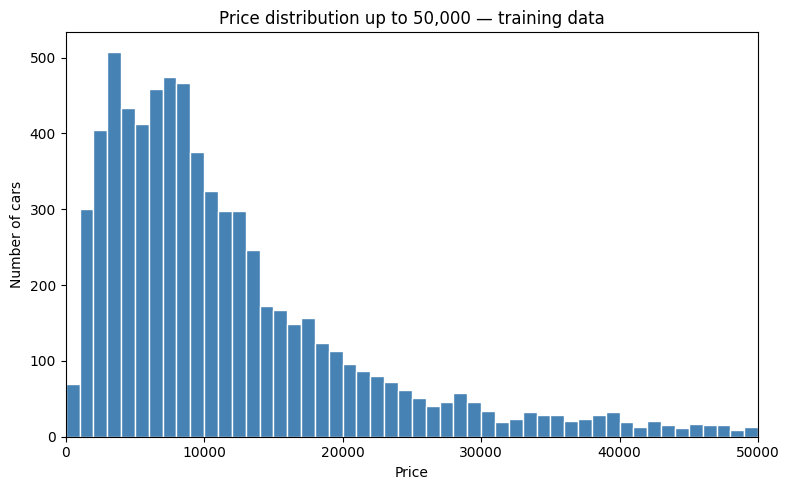

In [19]:
price_limit = 50000
print(f"Cars shown: {(y_train <= price_limit).sum()} of {len(y_train)}")
print(f"Cars above this view: {(y_train > price_limit).sum()}")

plt.figure(figsize=(8, 5))
plt.hist(y_train, bins=50, range=(0, price_limit), color="steelblue", edgecolor="white")
plt.xlim(0, price_limit)
plt.title("Price distribution up to 50,000 — training data")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

### 7.2 Price and year

Each dot is one car. We can look for a relationship between the car's year and its price.


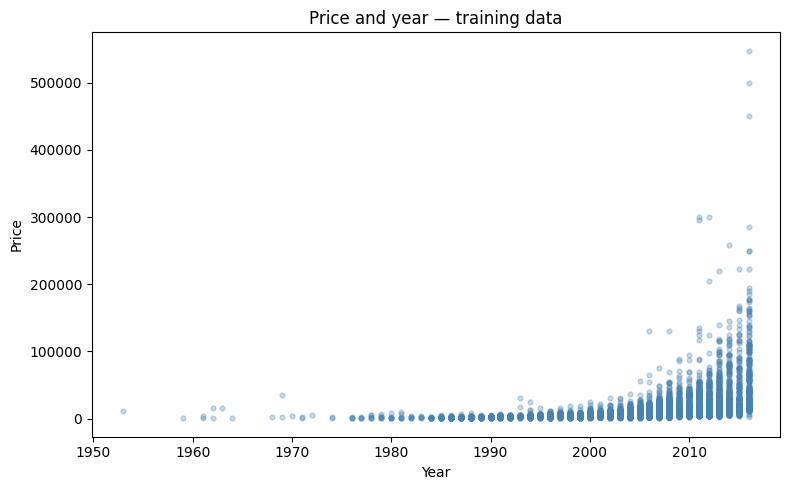

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["year"], y_train, s=12, alpha=0.3, color="steelblue")
plt.title("Price and year — training data")
plt.xlabel("Year")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

### 7.3 Price and mileage

Each dot is one car. We can look for a relationship between mileage and price.


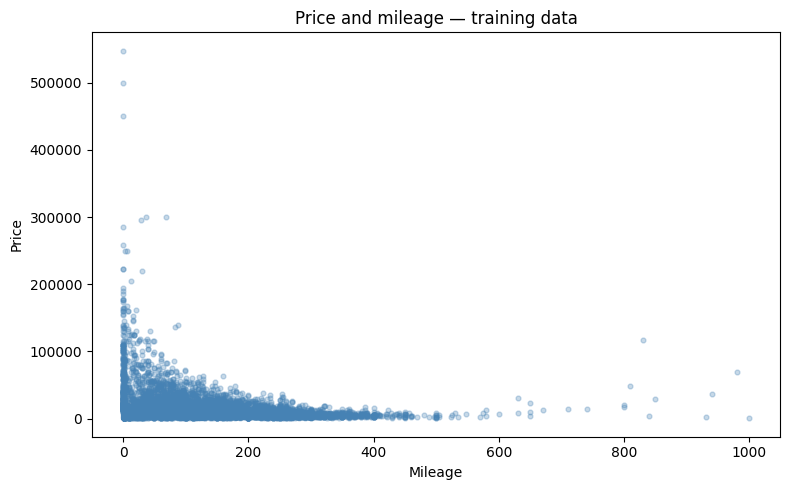

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["mileage"], y_train, s=12, alpha=0.3, color="steelblue")
plt.title("Price and mileage — training data")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

## 8. Prepare input features

We use one-hot encoding for text and standardization for mileage and year. We fit these steps using training data only. The code matches `create_preprocessor()` in `model_training.py`.


### 8.1 Set up the preparation

`StandardScaler` puts mileage and year on comparable scales. `OneHotEncoder` creates a 0/1 column for each text category. `ColumnTransformer` applies the right method to each group of columns.

`handle_unknown="ignore"` lets us process a category that was not present during fitting; its category columns will be zero.


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["mileage", "year"]
categorical_features = ["car", "body", "engType", "registration", "model", "drive"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

### 8.2 Prepare the training rows

`fit_transform()` learns the scaling values and category names from `X_train`, then converts it to numeric inputs. We keep `price` unchanged and leave the test set aside.


In [23]:
X_train_prepared = preprocessor.fit_transform(X_train)
print(f"Rows: {X_train_prepared.shape[0]}")
print(f"Features before preparation: {X_train.shape[1]}")
print(f"Features after preparation: {X_train_prepared.shape[1]}")

Rows: 7370
Features before preparation: 8
Features after preparation: 919


### 8.3 See the scaled numbers

This table compares the original and scaled values for five training cars. A negative scaled value means it is below the training average. Scaling changes the scale, not the underlying information.


In [24]:
# Convert just five rows to a normal table so we can inspect them.
prepared_example = pd.DataFrame(
    X_train_prepared[:5].toarray(),
    columns=preprocessor.get_feature_names_out(),
    index=X_train.head().index,
)

numeric_example = X_train[["mileage", "year"]].head().copy()
numeric_example["mileage_scaled"] = prepared_example["numeric__mileage"]
numeric_example["year_scaled"] = prepared_example["numeric__year"]
numeric_example.round(2)

,mileage,year,mileage_scaled,year_scaled
5719,1,2004,-1.42,-0.35
445,120,2008,-0.21,0.22
370,163,2011,0.22,0.64
9386,194,2008,0.54,0.22
1086,120,2012,-0.21,0.79


### 8.4 See the encoded drive categories

A value of 1 means the car belongs to that category; 0 means it does not. `unknown` is its own category, just like front, rear, and full drive.


In [25]:
drive_example = prepared_example.filter(like="drive_").copy()
drive_example["drive_before_encoding"] = X_train["drive"].head()
drive_example

,categorical__drive_front,categorical__drive_full,categorical__drive_rear,categorical__drive_unknown,drive_before_encoding
5719,0.0,0.0,0.0,1.0,unknown
445,1.0,0.0,0.0,0.0,front
370,0.0,1.0,0.0,0.0,full
9386,0.0,1.0,0.0,0.0,full
1086,1.0,0.0,0.0,0.0,front


## 9. Train the first regression model

We train linear regression using the prepared features and training prices. We compare this first model with other models later.


### 9.1 Combine preparation and the model

A `Pipeline` runs preparation followed by regression. We give it the original input columns; it handles scaling and encoding. This is the same setup as `create_model()` in `model_training.py`.


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from model_training import create_preprocessor

model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", LinearRegression()),
])

### 9.2 Train the model

`fit()` learns from the training cars and their known prices. The pipeline fits both the preparation and regression using training data only.


In [27]:
model.fit(X_train, y_train)
print(f"Linear regression trained on {len(X_train)} cars.")

Linear regression trained on 7370 cars.


### 9.3 Show example predictions

We predict prices for five training cars and compare them with their actual prices. The model has already seen these cars, so these examples do not tell us how well it predicts new cars. Validation comes in the next step.


In [28]:
examples = X_train[["car", "model", "year", "mileage"]].head().copy()
examples["actual_price"] = y_train.head()
examples["predicted_price"] = model.predict(X_train.head())
examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5719,Volkswagen,T5 (Transporter) Passenger,2004,1,9750.0,13798.69
445,Honda,Accord,2008,120,13700.0,14186.67
370,BMW,X5 M,2011,163,34600.0,74343.08
9386,Mitsubishi,Pajero Wagon,2008,194,17500.0,18575.30
1086,Volkswagen,Scirocco,2012,120,19100.0,20596.37


### 9.4 Plot the training predictions

Each dot compares one training car's actual and predicted price. A dot on the dashed line is an exact match. This is a view of the training fit; the test set remains aside.

Linear regression can predict negative prices because it does not restrict the output to positive values. We keep the raw predictions visible for review.


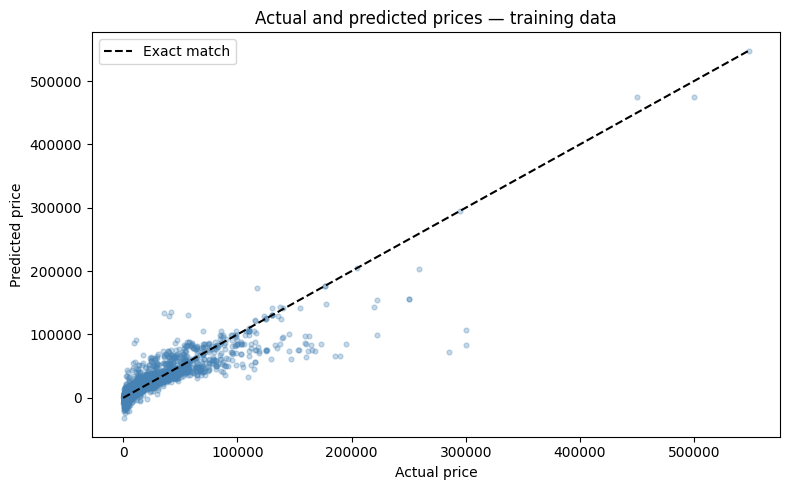

In [29]:
training_predictions = model.predict(X_train)
price_max = max(y_train.max(), training_predictions.max())

plt.figure(figsize=(8, 5))
plt.scatter(y_train, training_predictions, s=12, alpha=0.3, color="steelblue")
plt.plot([0, price_max], [0, price_max], "k--", label="Exact match")
plt.title("Actual and predicted prices — training data")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Validate linear regression

We check predictions on cars the model has not trained on using five-fold cross-validation.

We divide the 7,370 training cars into five parts. Each round trains on four parts (5,896 cars) and validates on the remaining part (1,474 cars). Every car is used for validation once. The 1,843 held-out test cars stay aside.


### 10.1 Run five-fold cross-validation

We pass a fresh pipeline to `cross_validate()`. It refits preprocessing and regression inside each fold. We use the original `X_train`, so preparation does not learn from the validation rows.

MAE is the average absolute price error. RMSE gives more weight to large errors. Both use the same units as price, and lower values are better.


In [30]:
from sklearn.model_selection import KFold, cross_validate
from model_training import create_model

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(
    create_model(),
    X_train,
    y_train,
    cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    return_train_score=True,
    error_score="raise",
)

### 10.2 Show the errors for each fold

Scikit-learn returns negative error scores, so we use a minus sign to show positive errors. Its `test_MAE` and `test_RMSE` keys refer to the validation fold, not our held-out test dataset. This is the same procedure used by `validate_linear_regression()` and `validate_model()` in `model_training.py`.


In [31]:
fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -scores["train_MAE"],
    "validation_MAE": -scores["test_MAE"],
    "training_RMSE": -scores["train_RMSE"],
    "validation_RMSE": -scores["test_RMSE"],
})
fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE
0,1,4460.98,6141.76,9407.91,17170.96
1,2,4617.23,6094.93,10305.32,12290.90
2,3,4681.54,6192.52,10443.05,14878.11
3,4,4594.53,5724.32,9977.72,14269.17
4,5,4481.06,5884.52,9605.78,14510.15


### 10.3 Summarize the five folds

`mean` is the average error across the folds. `std` shows how much the errors vary between folds. Comparing training and validation errors helps us see whether performance drops on unseen cars.


In [32]:
summary = fold_results.drop(columns=["fold"]).agg(["mean", "std"]).T
summary.round(2)

,mean,std
training_MAE,4567.07,93.58
validation_MAE,6007.61,196.99
training_RMSE,9947.96,442.28
validation_RMSE,14623.86,1741.68


## 11. Train and validate a decision tree

We train a decision tree using the same prepared features. We start with default tree settings and `random_state=42` to make training repeatable. We compare its errors with linear regression using the same five folds. The held-out test set stays aside.


### 11.1 Create the decision tree pipeline

We use the same preparation as linear regression and replace the regressor. Trees do not require numeric scaling, but we keep the existing preparation for this first comparison. This matches `create_decision_tree_model()` in `model_training.py`.


In [33]:
from sklearn.tree import DecisionTreeRegressor
from model_training import create_decision_tree_model

tree_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", DecisionTreeRegressor(random_state=42)),
])

### 11.2 Train and show example predictions

The table shows five training cars. These examples illustrate the fitted tree; validation below measures predictions for cars it has not trained on.


In [34]:
tree_model.fit(X_train, y_train)

tree_examples = X_train[["car", "model", "year", "mileage"]].head().copy()
tree_examples["actual_price"] = y_train.head()
tree_examples["predicted_price"] = tree_model.predict(X_train.head())
tree_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5719,Volkswagen,T5 (Transporter) Passenger,2004,1,9750.0,9750.0
445,Honda,Accord,2008,120,13700.0,13700.0
370,BMW,X5 M,2011,163,34600.0,34600.0
9386,Mitsubishi,Pajero Wagon,2008,194,17500.0,17500.0
1086,Volkswagen,Scirocco,2012,120,19100.0,19100.0


### 11.3 Validate using the same five folds

We reuse `cv` from section 10 so both models are evaluated on exactly the same folds. A fresh tree pipeline is fitted within each fold, using the original inputs rather than already prepared data.


In [35]:
tree_scores = cross_validate(
    create_decision_tree_model(),
    X_train,
    y_train,
    cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    return_train_score=True,
    error_score="raise",
)

### 11.4 Show decision tree errors

We show positive MAE and RMSE for training and validation, using the same calculation as section 10.


In [36]:
tree_fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -tree_scores["train_MAE"],
    "validation_MAE": -tree_scores["test_MAE"],
    "training_RMSE": -tree_scores["train_RMSE"],
    "validation_RMSE": -tree_scores["test_RMSE"],
})
tree_fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE
0,1,56.07,4239.02,754.22,16371.25
1,2,83.54,3903.11,1268.75,11059.99
2,3,76.55,3825.93,1167.35,15452.25
3,4,83.41,3828.81,1201.73,12709.01
4,5,89.78,3929.05,1307.49,13047.79


### 11.5 Compare with linear regression

These are the mean errors across the same five folds. Lower validation errors are better. A large gap between training and validation errors suggests overfitting. Low training error alone does not mean the model predicts new cars well.


In [37]:
comparison = pd.DataFrame({
    "Linear regression": fold_results.drop(columns=["fold"]).mean(),
    "Decision tree": tree_fold_results.drop(columns=["fold"]).mean(),
}).T
comparison.round(2)

,training_MAE,validation_MAE,training_RMSE,validation_RMSE
Linear regression,4567.07,6007.61,9947.96,14623.86
Decision tree,77.87,3945.19,1139.91,13728.06


## 12. Train and validate a random forest

We train a random forest with 100 trees and compare it with the other models. For regression, the forest averages the trees' predictions.

`max_features="sqrt"` lets each split consider a random subset of the input features. `random_state=42` makes training repeatable. These are our starting settings. Tuning comes later.


### 12.1 Create the random forest pipeline

We keep the same feature preparation and replace the regressor. This matches `create_random_forest_model()` in `model_training.py`.


In [38]:
from sklearn.ensemble import RandomForestRegressor
from model_training import create_random_forest_model

forest_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("regressor", RandomForestRegressor(
        n_estimators=100, max_features="sqrt", random_state=42
    )),
])

### 12.2 Train and show example predictions

These five cars are from the training data. The table illustrates the fitted forest; validation below checks predictions for unseen cars.


In [39]:
forest_model.fit(X_train, y_train)

forest_examples = X_train[["car", "model", "year", "mileage"]].head().copy()
forest_examples["actual_price"] = y_train.head()
forest_examples["predicted_price"] = forest_model.predict(X_train.head())
forest_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price
5719,Volkswagen,T5 (Transporter) Passenger,2004,1,9750.0,9806.97
445,Honda,Accord,2008,120,13700.0,13939.66
370,BMW,X5 M,2011,163,34600.0,38751.68
9386,Mitsubishi,Pajero Wagon,2008,194,17500.0,17517.99
1086,Volkswagen,Scirocco,2012,120,19100.0,18604.10


### 12.3 Validate using the same five folds

We reuse `cv` from section 10. The forest and its preparation are fitted again inside each fold. The held-out test set remains aside.


In [40]:
forest_scores = cross_validate(
    create_random_forest_model(),
    X_train,
    y_train,
    cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    return_train_score=True,
    error_score="raise",
)

### 12.4 Show random forest errors

We show positive training and validation errors using the same metrics as the other models.


In [41]:
forest_fold_results = pd.DataFrame({
    "fold": range(1, 6),
    "training_MAE": -forest_scores["train_MAE"],
    "validation_MAE": -forest_scores["test_MAE"],
    "training_RMSE": -forest_scores["train_RMSE"],
    "validation_RMSE": -forest_scores["test_RMSE"],
})
forest_fold_results.round(2)

,fold,training_MAE,validation_MAE,training_RMSE,validation_RMSE
0,1,1266.82,3176.71,4396.14,9712.50
1,2,1291.87,3269.90,4342.08,8246.92
2,3,1283.46,3418.08,4285.56,14411.80
3,4,1327.29,3310.16,4736.15,11262.82
4,5,1250.04,3362.11,3892.08,10628.63


### 12.5 Compare all three models

These are mean errors across the same five folds. Lower validation errors are better. Compare the training and validation errors as well: a forest can still overfit.


In [42]:
comparison = pd.DataFrame({
    "Linear regression": fold_results.drop(columns=["fold"]).mean(),
    "Decision tree": tree_fold_results.drop(columns=["fold"]).mean(),
    "Random forest": forest_fold_results.drop(columns=["fold"]).mean(),
}).T
comparison.round(2)

,training_MAE,validation_MAE,training_RMSE,validation_RMSE
Linear regression,4567.07,6007.61,9947.96,14623.86
Decision tree,77.87,3945.19,1139.91,13728.06
Random forest,1283.90,3307.39,4330.40,10852.54


## 13. Tune the random forest

We try nine combinations using the same five folds. These values are our project choices. We select the lowest validation MAE and also report RMSE. The held-out test set stays aside.


### 13.1 Choose the settings to try

`max_depth` limits the number of levels in each tree; `None` means unlimited. `min_samples_leaf` sets the minimum number of cars in each final group. The `regressor__` prefix tells the pipeline which step to change.

We keep 100 trees and include the original settings: unlimited depth and one car per leaf. `refit="MAE"` selects by MAE and then trains the selected pipeline on all training rows. This matches `tune_random_forest()` in `model_training.py`.


In [43]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "regressor__max_depth": [None, 20, 40],
    "regressor__min_samples_leaf": [1, 2, 5],
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    create_random_forest_model(),
    param_grid=param_grid,
    cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    refit="MAE",
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

### 13.2 Run the search

There are nine setting combinations and five folds, giving 45 fits for validation. Each fit learns its own preparation from the fold's training rows. The selected pipeline is fitted once more using all 7,370 training rows.


In [44]:
grid_search.fit(X_train, y_train)
print("Grid search finished.")

Fitting 5 folds for each of 9 candidates, totalling 45 fits


Grid search finished.


### 13.3 Show all combinations

The table is sorted by validation MAE, with lower errors first. All errors are averages across the five folds. `unlimited` means no depth limit. This matches `summarize_tuning()` in `model_training.py`.


In [45]:
scores = grid_search.cv_results_
grid_results = pd.DataFrame({
    "max_depth": pd.Series(scores["param_regressor__max_depth"], dtype=object),
    "min_samples_leaf": scores["param_regressor__min_samples_leaf"],
    "training_MAE": -scores["mean_train_MAE"],
    "validation_MAE": -scores["mean_test_MAE"],
    "training_RMSE": -scores["mean_train_RMSE"],
    "validation_RMSE": -scores["mean_test_RMSE"],
})
grid_results["max_depth"] = grid_results["max_depth"].fillna("unlimited")
grid_results = grid_results.sort_values("validation_MAE")
grid_results.round(2)

,max_depth,min_samples_leaf,training_MAE,validation_MAE,training_RMSE,validation_RMSE
0,unlimited,1,1283.90,3307.39,4330.40,10852.54
6,40,1,2265.88,3802.83,5194.82,11303.44
1,unlimited,2,5043.21,5453.09,13268.88,14812.59
7,40,2,5071.45,5485.65,13194.27,14744.68
3,20,1,5062.55,5669.94,9986.42,13612.53
4,20,2,5957.50,6259.71,14254.22,15529.76
2,unlimited,5,6730.49,6908.65,16841.89,17111.04
8,40,5,6735.57,6915.28,16845.14,17128.25
5,20,5,7002.13,7159.33,17126.92,17390.45


### 13.4 Compare the selected settings with the initial forest

We compare both versions using the same validation folds. The selected settings may be the original settings if none of the others improves validation MAE. These scores helped choose the settings; final test performance is still unknown.


In [46]:
print(f"Selected settings: {grid_search.best_params_}")
tuned_errors = grid_results.loc[grid_search.best_index_, comparison.columns].astype(float)
tuning_comparison = pd.DataFrame({
    "Initial random forest": comparison.loc["Random forest"],
    "Selected random forest": tuned_errors,
}).T
tuning_comparison.round(2)

Selected settings: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1}


,training_MAE,validation_MAE,training_RMSE,validation_RMSE
Initial random forest,1283.9,3307.39,4330.4,10852.54
Selected random forest,1283.9,3307.39,4330.4,10852.54


### 13.5 Keep the selected pipeline

`best_estimator_` contains the selected forest and its preparation, already fitted on all training rows. This is the fitted pipeline we evaluate in the next section.


In [47]:
best_model = grid_search.best_estimator_
print(f"Selected pipeline fitted on {len(X_train)} training cars.")

Selected pipeline fitted on 7370 training cars.


## 14. Final test evaluation

We evaluate the selected model after comparing and tuning models. `best_model` is already fitted on all 7,370 training rows. Its settings were selected before looking at these test results.

We now use the 1,843 held-out test rows. We keep the selected model fixed and report MAE and RMSE.


### 14.1 Predict test prices and calculate errors

`predict()` uses the preparation already learned from training data. We do not call `fit()` on the test rows. This matches `evaluate_final_model()` in `model_training.py`.


In [48]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

test_predictions = best_model.predict(X_test)
test_results = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, test_predictions)],
    "RMSE": [root_mean_squared_error(y_test, test_predictions)],
}, index=["Held-out test"])
print(f"Test rows evaluated: {len(X_test)}")
test_results.round(2)

Test rows evaluated: 1843


,MAE,RMSE
Held-out test,3080.42,8439.55


### 14.2 Compare validation and final test errors

The validation row is the average across five folds used during model selection. The test row evaluates the selected pipeline on held-out cars. Different cars and training sizes mean the errors can differ.

We record these final test results without using them to change settings.


In [49]:
final_comparison = pd.DataFrame({
    "MAE": [tuning_comparison.loc["Selected random forest", "validation_MAE"],
            test_results.loc["Held-out test", "MAE"]],
    "RMSE": [tuning_comparison.loc["Selected random forest", "validation_RMSE"],
             test_results.loc["Held-out test", "RMSE"]],
}, index=["Cross-validation (mean)", "Held-out test"])
final_comparison.round(2)

,MAE,RMSE
Cross-validation (mean),3307.39,10852.54
Held-out test,3080.42,8439.55


### 14.3 Show five test predictions

We show the first five test cars using the predictions already calculated above. `absolute_error` is the size of the difference between the actual and predicted price.


In [50]:
test_examples = X_test[["car", "model", "year", "mileage"]].head().copy()
test_examples["actual_price"] = y_test.head()
test_examples["predicted_price"] = test_predictions[:5]
test_examples["absolute_error"] = (
    test_examples["actual_price"] - test_examples["predicted_price"]
).abs()
test_examples.round(2)

,car,model,year,mileage,actual_price,predicted_price,absolute_error
8514,Opel,Calibra,1992,240,6000.0,3787.47,2212.53
6464,Mercedes-Benz,230,1985,30,2650.0,11249.50,8599.50
1014,Mitsubishi,Lancer X,2008,96,8900.0,8896.81,3.19
8285,Kia,Rio,2013,55,10300.0,10865.80,565.80
7317,Opel,Vivaro Passenger,2006,220,10800.0,8729.99,2070.01


## 15. Save the selected pipeline

We save the fitted preprocessing and random forest together using `joblib`, so they can be loaded for later predictions.

The saved pipeline expects mileage in thousands: 68 represents 68,000. Saving does not train the model again. This matches `save_pipeline()` in `model_training.py`.


In [ ]:
import joblib
from model_training import MODEL_PATH

MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"Saved pipeline to {MODEL_PATH}")